# Gråtone- og binære bilder


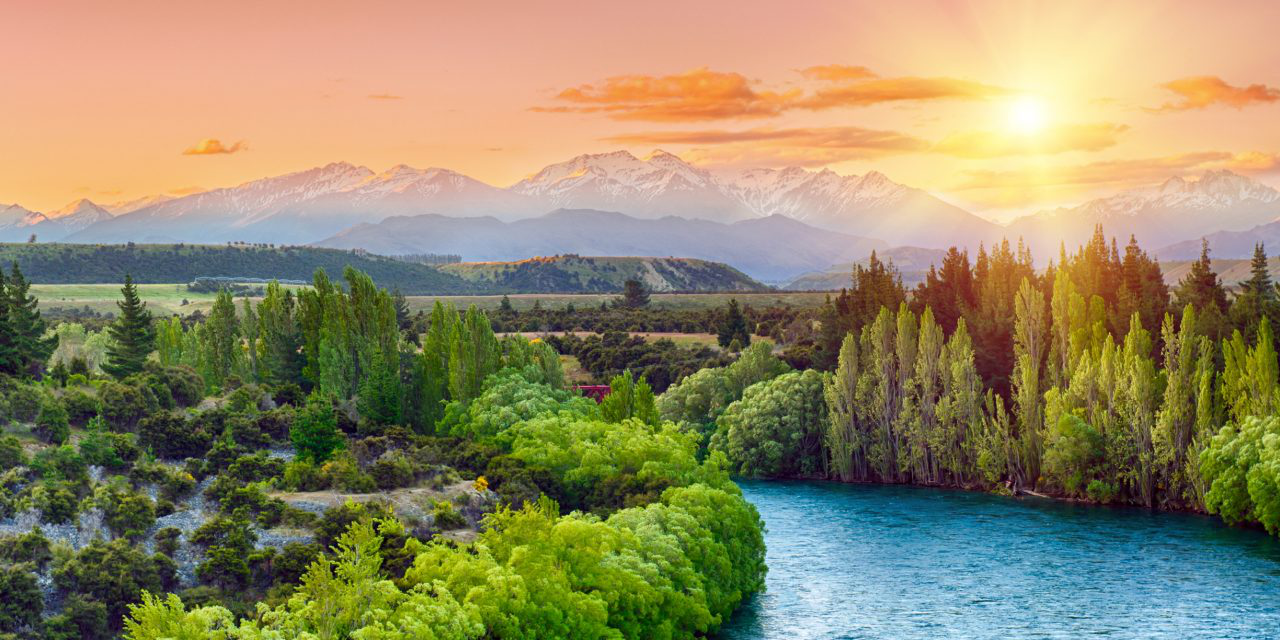

In [1]:
import cv2
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact

img         = cv2.imread("nature.png")
img_gray    = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

cv2.imshow("Bilde", img)


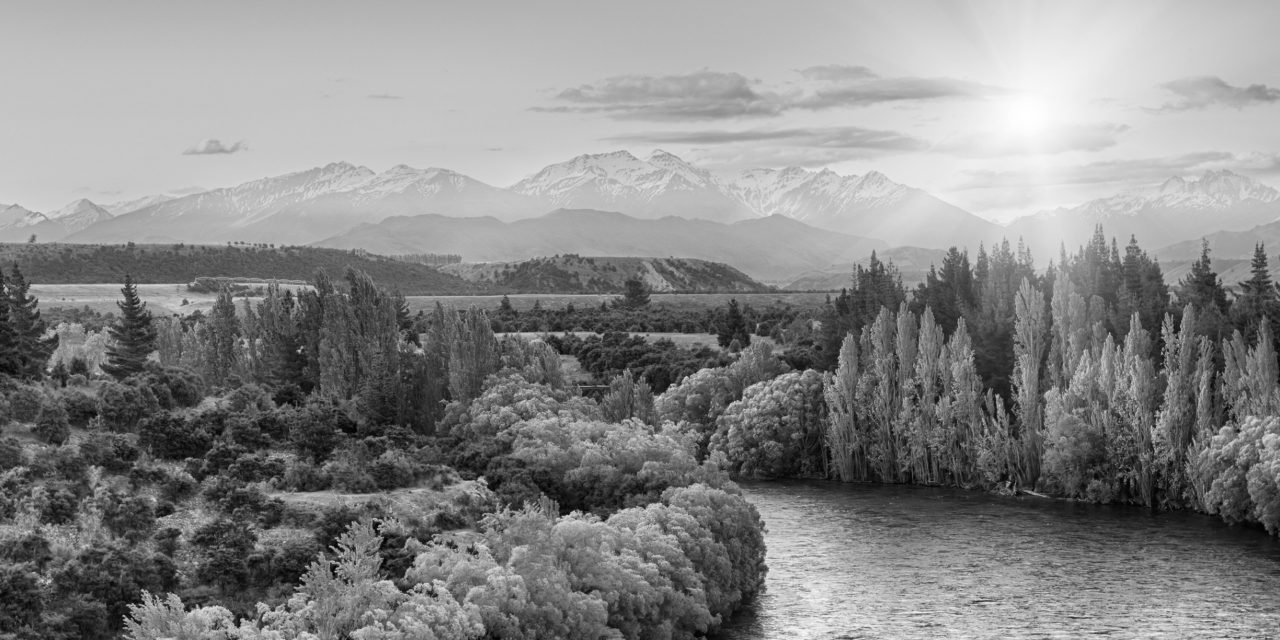

In [2]:
img         = cv2.imread("nature.png")
img_gray    = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

cv2.imshow("Bilde", img_gray)

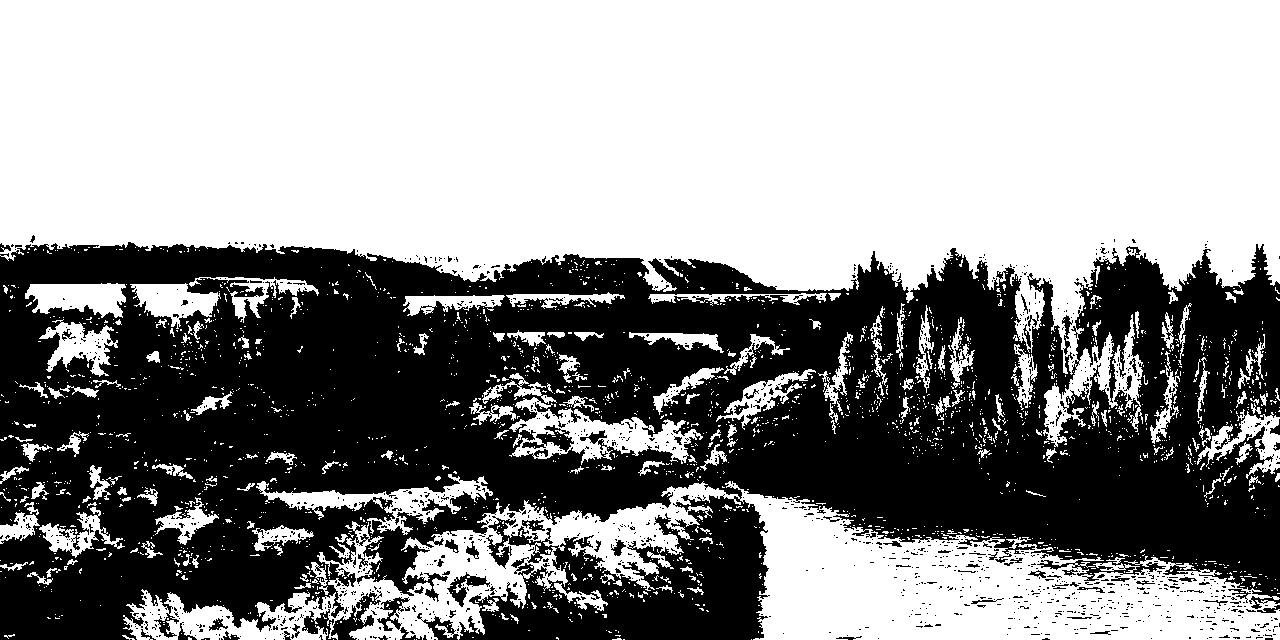

[[255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 [255 255 255 ... 255 255 255]
 ...
 [  0   0   0 ... 255 255 255]
 [  0   0   0 ... 255 255 255]
 [  0   0   0 ... 255 255 255]]


In [3]:
img         = cv2.imread("nature.png")
img_gray    = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

@interact(thresh=(0, 255))
def terskel(thresh=127):
    _, ut = cv2.threshold(img_gray, thresh, 255, cv2.THRESH_BINARY) 
    cv2.imshow("resultat", ut)
    print(ut)
 

# Blurred Images

Text(0.5, 1.0, 'gaussianFilter_15x15')

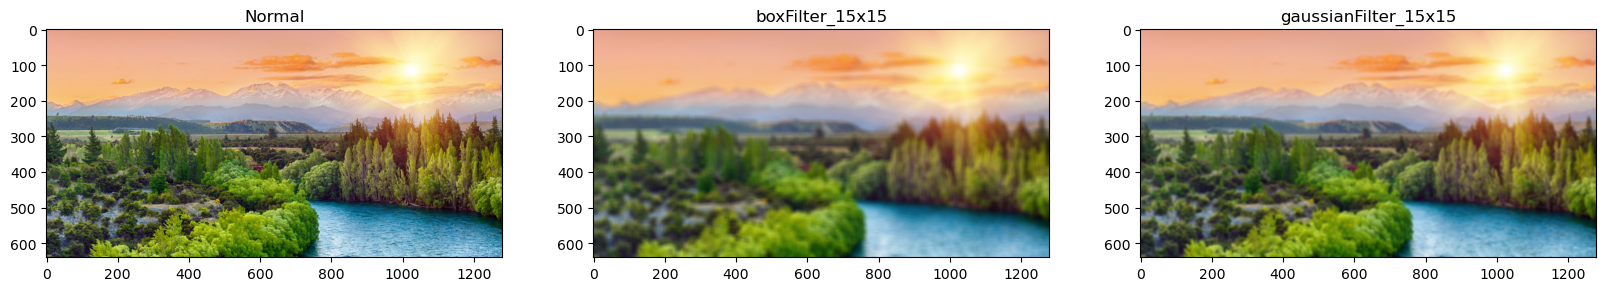

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# img = cv2.imread("Checkerboard_pattern.png")
img = cv2.imread("nature.png")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

boxFilter_7x7       = cv2.boxFilter(img, -1, (15, 15))
gaussianBlur_7x7    = cv2.GaussianBlur(img, (15, 15), 0)



# -------------------------------------------------------------------------
plt.figure(figsize=[20, 5])
plt.subplot(131); plt.imshow(img); plt.title("Normal")
plt.subplot(132); plt.imshow(boxFilter_7x7); plt.title("boxFilter_15x15")
plt.subplot(133); plt.imshow(gaussianBlur_7x7); plt.title("gaussianFilter_15x15")


Sobel linjer

Text(0.5, 1.0, 'sobel_y')

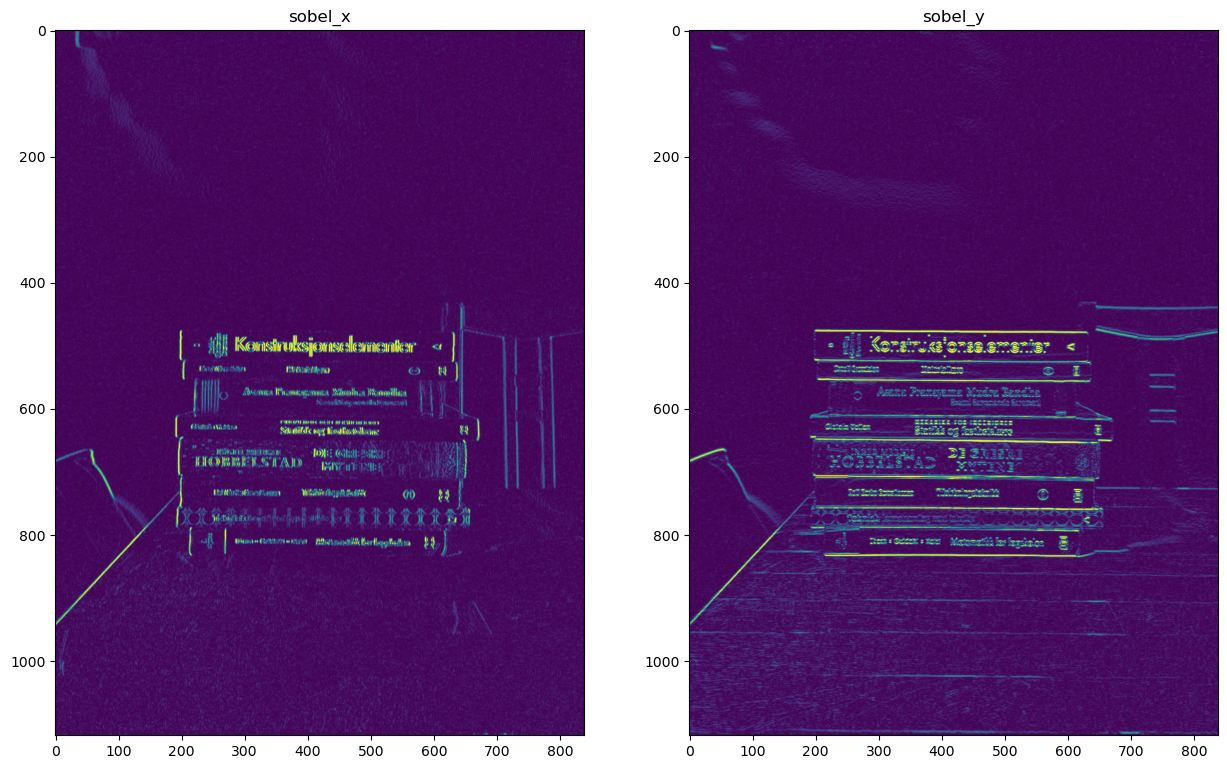

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# img = cv2.imread("Checkerboard_pattern.png")
img = cv2.imread("stack_1.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray = cv2.GaussianBlur(gray, (3, 3), 0)

# Sobel is a derivative: it measures how fast the brightness changes.
#   dx=1, dy=0 -> change from left to right  -> finds VERTICAL edges
#   dx=0, dy=1 -> change from top to bottom  -> finds HORIZONTAL edges
# ksize=3 uses these 3x3 kernels:
#   x: [-1 0 1]    y: [-1 -2 -1]
#      [-2 0 2]       [ 0  0  0]
#      [-1 0 1]       [ 1  2  1]
# The output depth must be a signed type (here 64-bit float). With uint8 the negative
# values (dark to bright is positive, bright to dark is negative) would be cut to 0
# and half of the edges would be lost.
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

# Take the absolute value so edges in both directions are shown, and scale to 0-255 (uint8)
abs_x = cv2.convertScaleAbs(sobel_x)
abs_y = cv2.convertScaleAbs(sobel_y)


# -------------------------------------------------------------------------
plt.figure(figsize=[15, 10])
plt.subplot(121); plt.imshow(abs_x); plt.title("sobel_x")
plt.subplot(122); plt.imshow(abs_y); plt.title("sobel_y")


Text(0.5, 1.0, 'strong_edges')

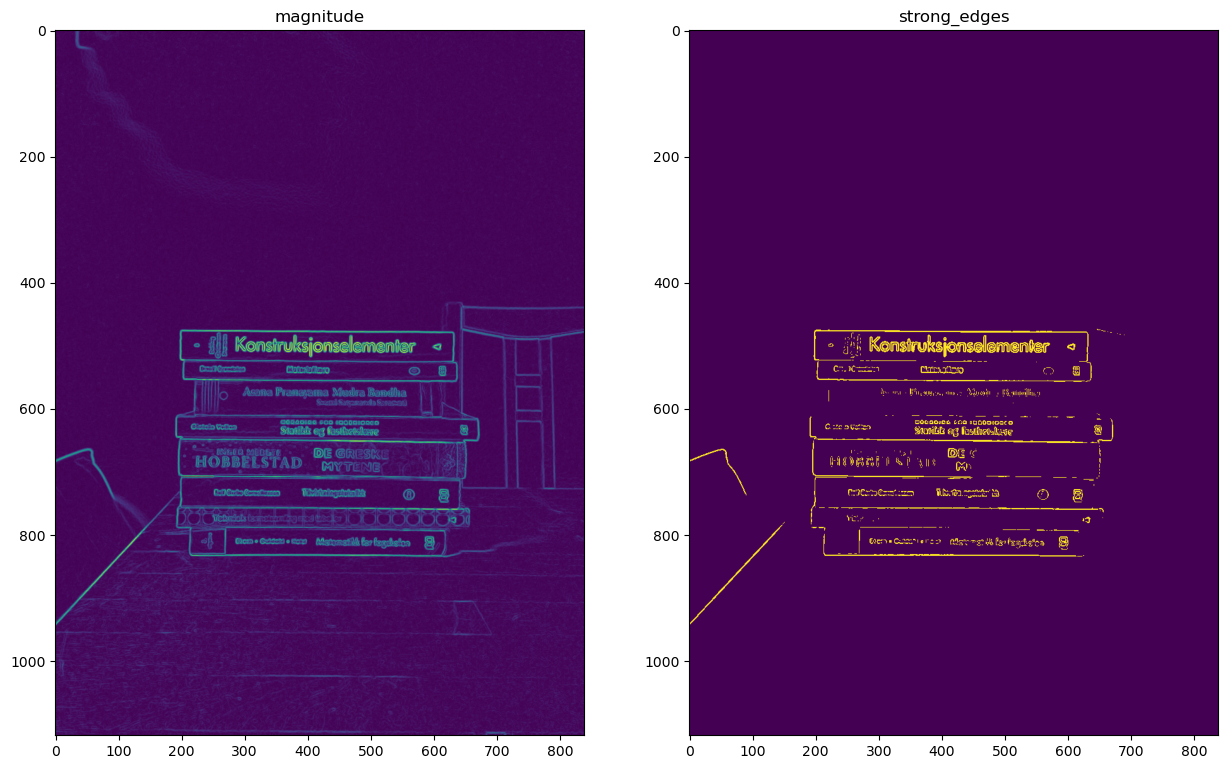

In [6]:
# Combine the two directions to the total edge strength (gradient magnitude): sqrt(x^2 + y^2)
magnitude = cv2.magnitude(sobel_x, sobel_y)
magnitude = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# Threshold: keep only the strong edges as white lines on a black background
_, strong_edges = cv2.threshold(magnitude, 100, 255, cv2.THRESH_BINARY)


# -------------------------------------------------------------------------
plt.figure(figsize=[15, 10])
plt.subplot(121); plt.imshow(magnitude); plt.title("magnitude")
plt.subplot(122); plt.imshow(strong_edges); plt.title("strong_edges")

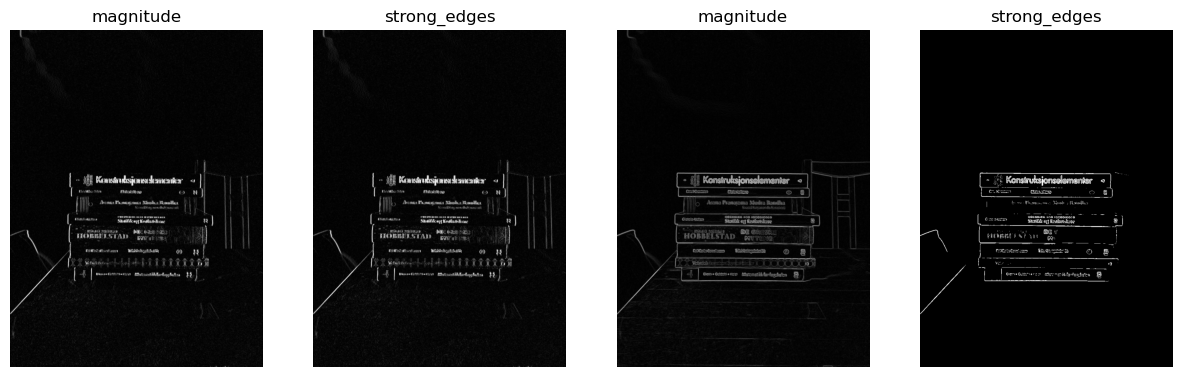

<function _show at 0x5bd64a0>

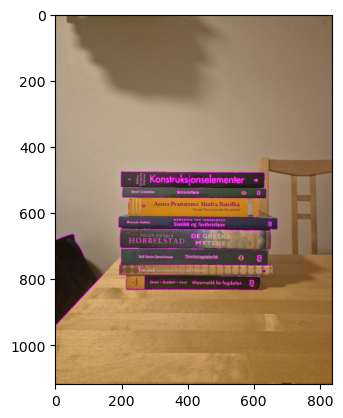

In [7]:


plt.figure(figsize=[15, 10])
plt.subplot(141); plt.imshow(cv2.cvtColor(abs_x, cv2.COLOR_GRAY2BGR)); plt.title("magnitude"); plt.axis('off')
plt.subplot(142); plt.imshow(cv2.cvtColor(abs_x, cv2.COLOR_GRAY2BGR)); plt.title("strong_edges"); plt.axis('off')
plt.subplot(143); plt.imshow(cv2.cvtColor(magnitude, cv2.COLOR_GRAY2BGR)); plt.title("magnitude"); plt.axis('off')
plt.subplot(144); plt.imshow(cv2.cvtColor(strong_edges, cv2.COLOR_GRAY2BGR)); plt.title("strong_edges"); plt.axis('off')
plt.show()


# Mark the strong edges on the original image: strong_edges is a mask (white = edge),
# and indexing with the mask sets the colour (B, G, R) of only those pixels.
marked = img.copy()
marked[strong_edges > 0] = (255, 0, 255)  # magenta
plt.imshow(marked)
plt.show


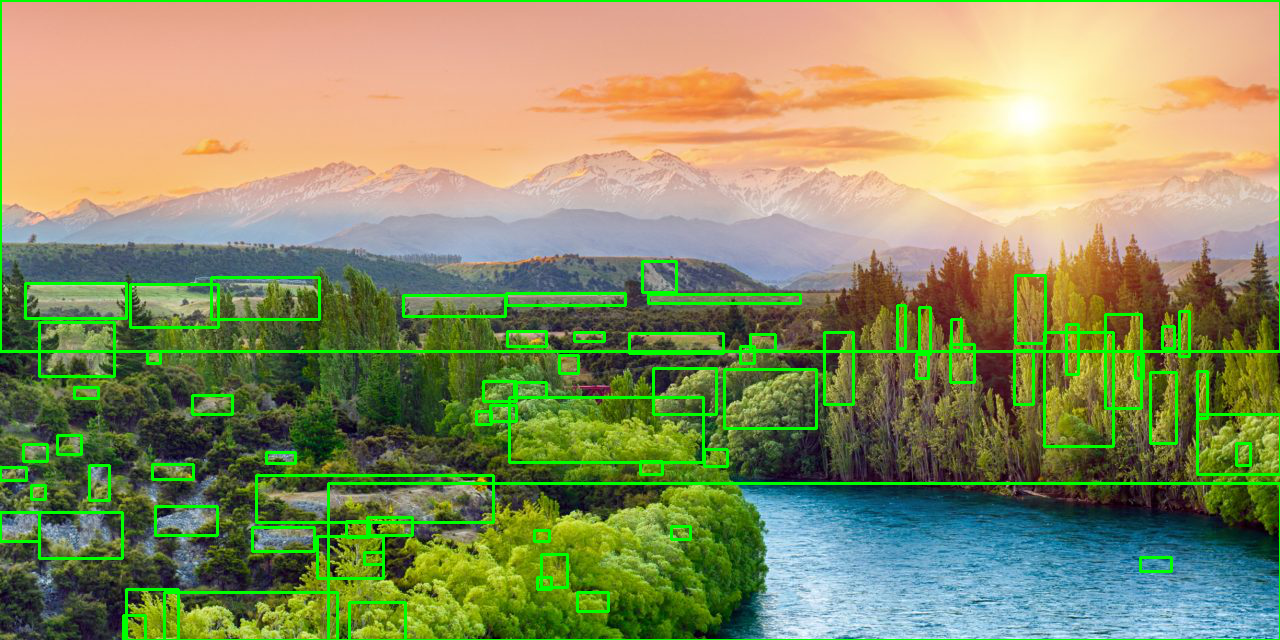

In [8]:
import cv2
import numpy as np

# 1. Load image and convert to grayscale
image = cv2.imread('nature.png')
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# 2. Threshold or apply edge detection to isolate shapes
_, thresh = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)

# 3. Find contours
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# 4. Loop through contours and apply cv2.boundingRect
for cnt in contours:
    # Filter out tiny noise contours using area
    if cv2.contourArea(cnt) > 50:
        # Get bounding rect coordinates
        x, y, w, h = cv2.boundingRect(cnt)
        
        # Draw the rectangle on the original image (Green box, 2px thickness)
        cv2.rectangle(image, (x, y), (x + w, y + h), (0, 255, 0), 2)

# 5. Display the result
cv2.imshow('Bounding Boxes', image)